# Dichotic left

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic_left')

7 of 7 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9239234 for dichotic_left. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9239234 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  22:21  9239234 pending  (0 min so far)
  22:30  9239234 running  (8 min so far)
Job 9239234 is done: all 7 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9239211     iggy def-ibruce_c cocktail-dicho   R 1-23:24:38     1   32        N/A    128G nc30411 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic_left_overt_masked_onsets-9239240.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:29:51 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:30:35 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components select

## Dichotic Left

In [5]:
# Loaded once here, reused by every unique-contribution/STRF/peak/
# waveform/attention-effect cell in this section - each one just
# reads a different predictor column out of this same fit instead
# of re-running the (expensive) TRF fit on FULL_BASE again.
data_full = load_trfs_saved(FULL_BASE, 'dichotic-left')

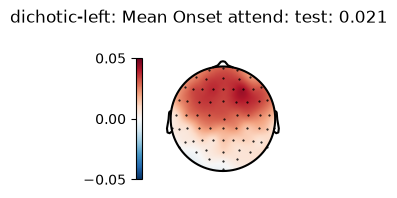

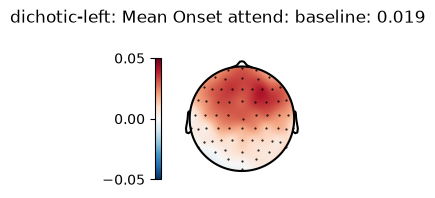

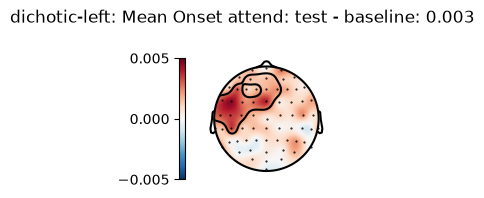

In [6]:
# Onset attend unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(ATTEND), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Onset attend', 'dichotic-left', onset(ATTEND))

In [7]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .036>

Onset attend (dichotic-left): ROI unique contribution t(12) = 2.136, p = 0.0270


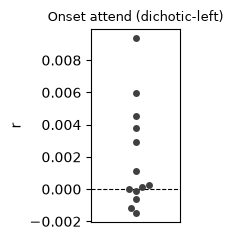

In [8]:
p = show_subject_swarm(diff, 'Onset attend', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


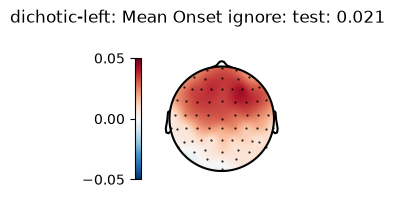

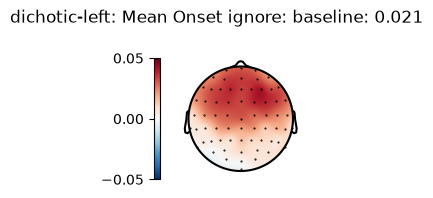

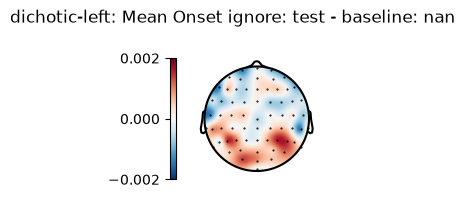

In [9]:
# Onset ignore unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(IGNORE), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Onset ignore', 'dichotic-left', onset(IGNORE))

In [10]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .428>

Onset ignore (dichotic-left): ROI unique contribution t(12) = -0.181, p = 0.5705


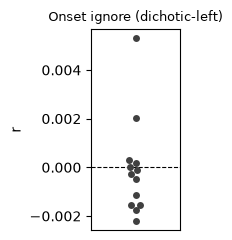

In [11]:
p = show_subject_swarm(diff, 'Onset ignore', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


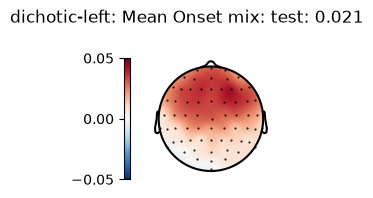

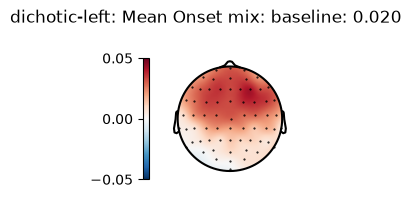

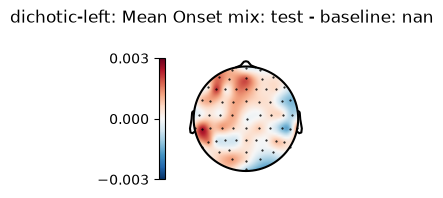

In [12]:
# Onset mix unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(MIX), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Onset mix', 'dichotic-left', onset(MIX))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .244>

Onset mix (dichotic-left): ROI unique contribution t(12) = 1.523, p = 0.0768


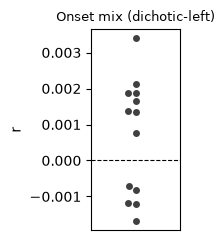

In [14]:
p = show_subject_swarm(diff, 'Onset mix', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


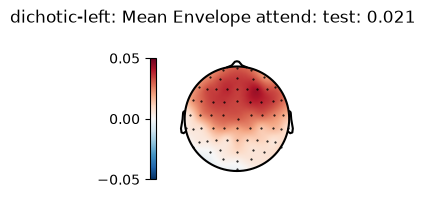

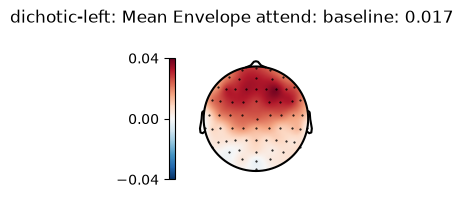

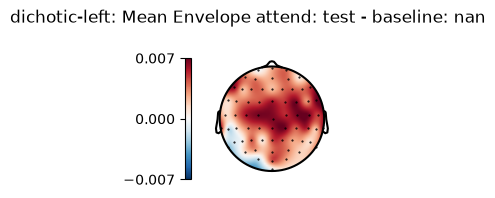

In [15]:
# Envelope attend unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(ATTEND), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Envelope attend', 'dichotic-left', envelope(ATTEND))

In [16]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 6 clusters, p = .066>

Envelope attend (dichotic-left): ROI unique contribution t(12) = 1.494, p = 0.0805


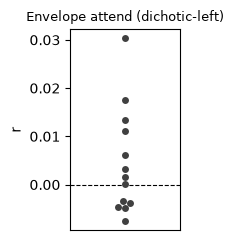

In [17]:
p = show_subject_swarm(diff, 'Envelope attend', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


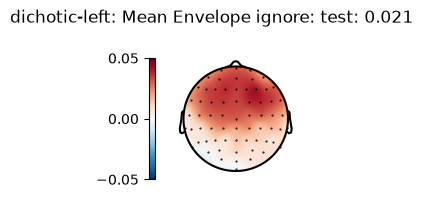

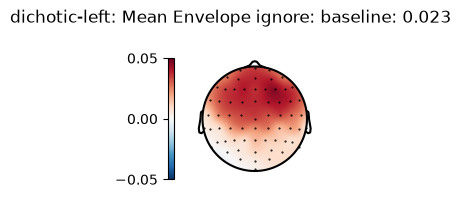

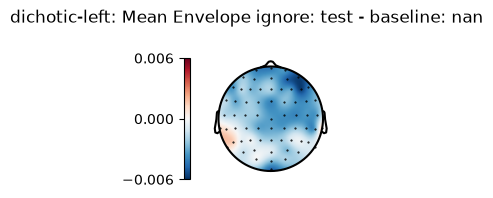

In [18]:
# Envelope ignore unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(IGNORE), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'dichotic-left', envelope(IGNORE))

In [19]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, no clusters>

Envelope ignore (dichotic-left): ROI unique contribution t(12) = -3.605, p = 0.9982


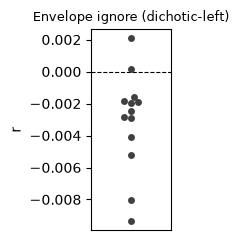

In [20]:
p = show_subject_swarm(diff, 'Envelope ignore', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


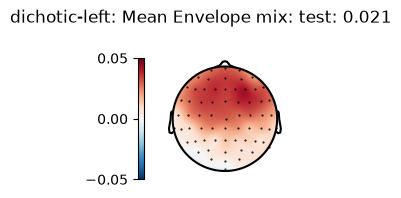

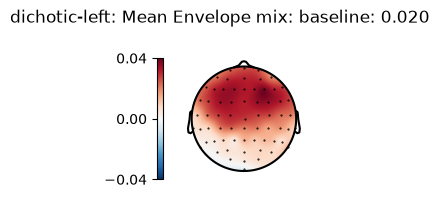

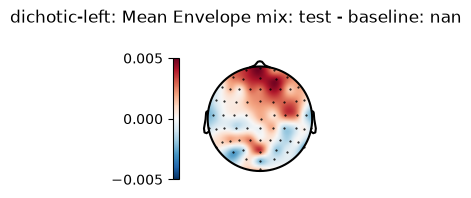

In [21]:
# Envelope mix unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(MIX), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Envelope mix', 'dichotic-left', envelope(MIX))

In [22]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .056>

Envelope mix (dichotic-left): ROI unique contribution t(12) = 1.507, p = 0.0788


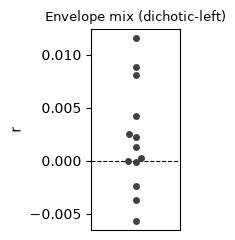

In [23]:
p = show_subject_swarm(diff, 'Envelope mix', 'dichotic-left')

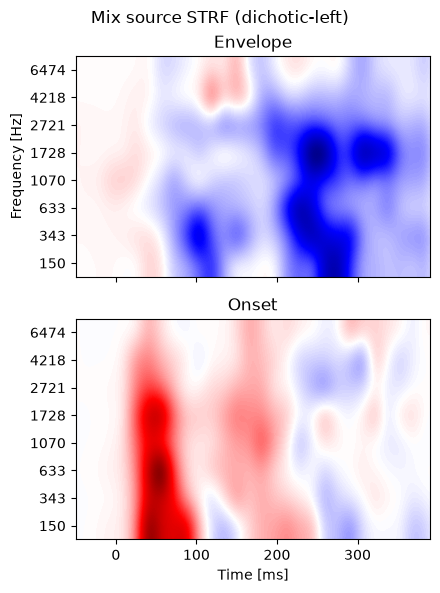

In [24]:
# Mix source STRF: envelope + onset (dichotic-left)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

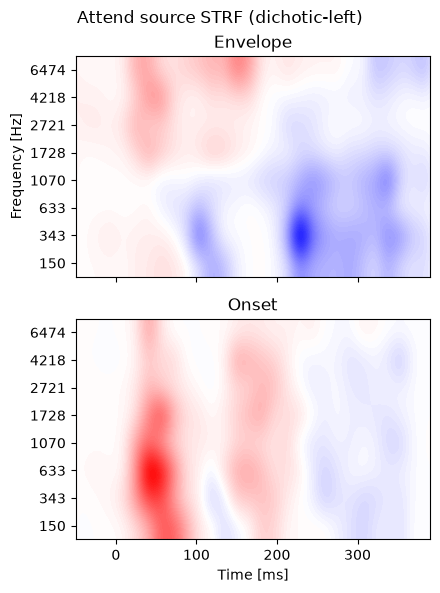

In [25]:
# Attend source STRF: envelope + onset (dichotic-left)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

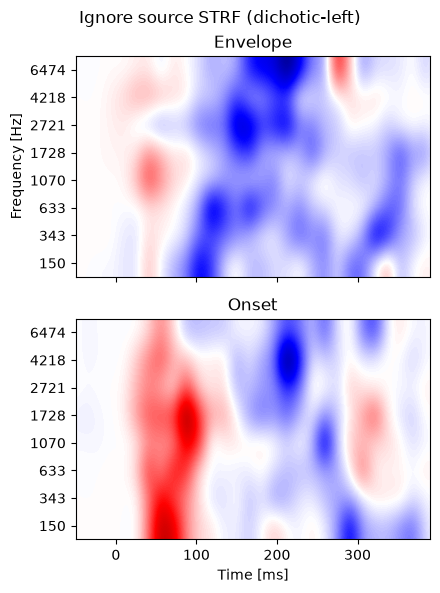

In [26]:
# Ignore source STRF: envelope + onset (dichotic-left)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [27]:
# Onset attend peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (dichotic-left) positive peak: 51 ms, amp 0.004205
Onset attend (dichotic-left) negative peak: 120 ms, amp -0.0006382


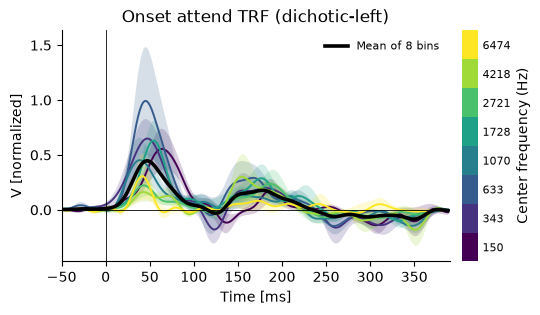

In [28]:
# Onset attend TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (dichotic-left)')

In [29]:
# Onset ignore peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (dichotic-left) positive peak: 61 ms, amp 0.001554
Onset ignore (dichotic-left) negative peak: 190 ms, amp -0.0005734


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


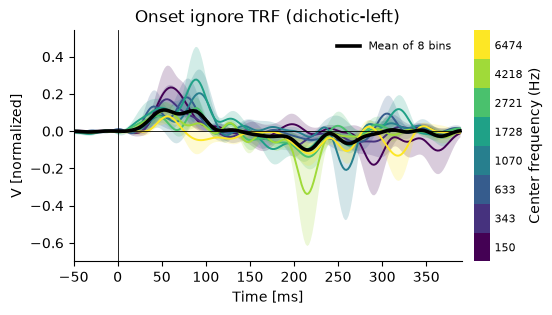

In [30]:
# Onset ignore TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (dichotic-left)')

In [31]:
# Onset mix peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (dichotic-left) positive peak: 50 ms, amp 0.003515
Onset mix (dichotic-left) negative peak: 115 ms, amp -0.0003083


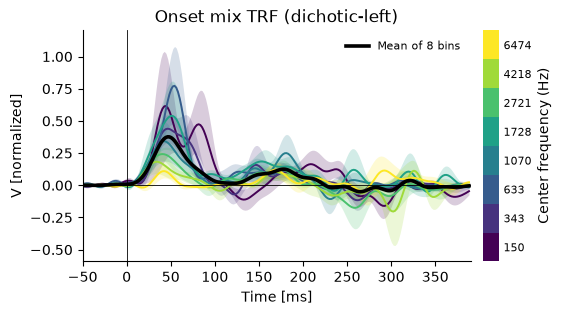

In [32]:
# Onset mix TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (dichotic-left)')

In [33]:
# Envelope attend peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (dichotic-left) positive peak: 46 ms, amp 0.001346
Envelope attend (dichotic-left) negative peak: 107 ms, amp -0.0009442


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (all) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


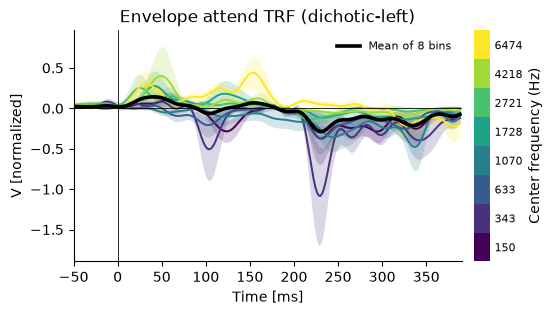

In [34]:
# Envelope attend TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (dichotic-left)')

In [35]:
# Envelope ignore peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (dichotic-left) positive peak: 46 ms, amp 0.0003664
Envelope ignore (dichotic-left) negative peak: 159 ms, amp -0.001102


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (all) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


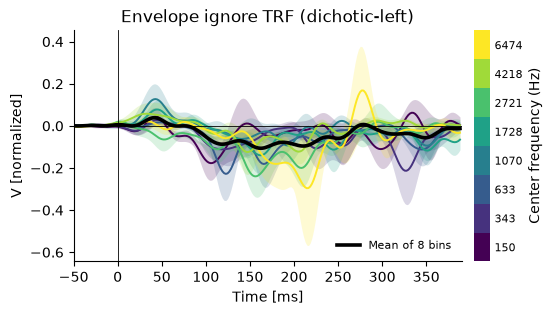

In [36]:
# Envelope ignore TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (dichotic-left)')

In [37]:
# Envelope mix peak amplitude & timing (dichotic-left)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (dichotic-left) positive peak: 49 ms, amp 0.0002157
Envelope mix (dichotic-left) negative peak: 103 ms, amp -0.001884


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (all) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


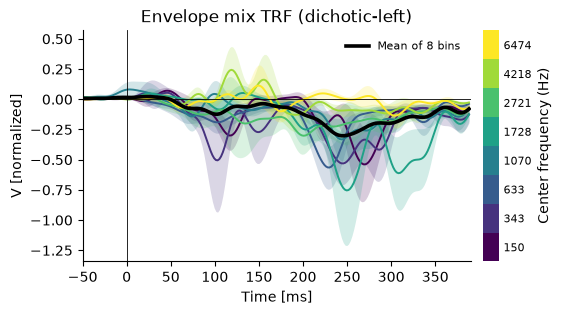

In [38]:
# Envelope mix TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (dichotic-left)')

In [39]:
# Onset peak comparison across mix, attend, and ignore (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


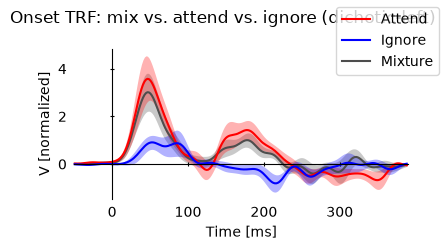

In [40]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (dichotic-left)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [41]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 60     0.0003963
02        mix                 48      0.001651
03        mix                 41      0.002861
04        mix                 43      0.001044
05        mix                 54      0.003493
06        mix                 41      0.003341
07        mix                 52      0.002497
08        mix                 45       0.01134
09        mix                 56      0.004351
10        mix                 54       0.00735
11        mix                 66      0.005159
12        mix                 41     0.0005814
13        mix                 46      0.001628
01        attend              64      0.001815
02        attend              56      0.003674
03        attend              52     0.0004716
04        attend              41      0.001952
05        attend              41       0.01468
06        attend              45      0.002812
07        attend              56      0.00471

In [42]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -0.26 p = .800,t12 = -3.80** p = .003
attend,,t12 = -2.47* p = .030


,attend,ignore
mix,t12 = -0.96 p = .358,t12 = -13.84*** p < .001
attend,,t12 = -11.15*** p < .001


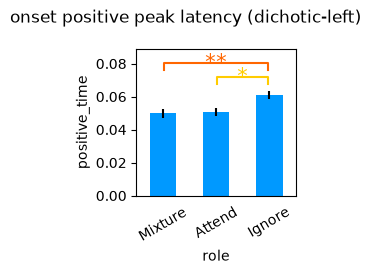

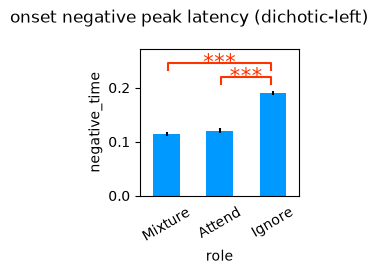

In [43]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (dichotic-left)')
p.set_xtick_rotation(30)

In [44]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -0.62 p = .547,t12 = 2.40* p = .034
attend,,t12 = 2.48* p = .029


,attend,ignore
mix,t12 = 1.20 p = .252,t12 = 0.77 p = .455
attend,,t12 = -0.13 p = .898


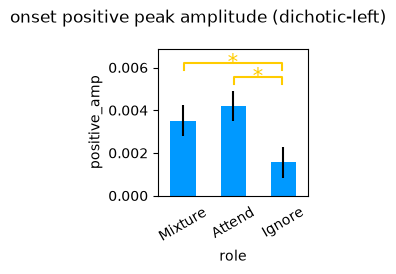

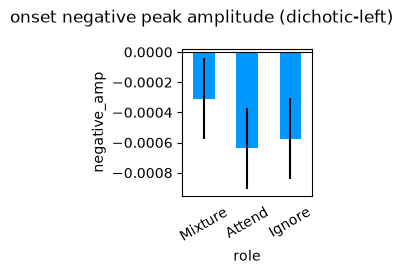

In [45]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)

In [46]:
# Envelope peak comparison across mix, attend, and ignore (dichotic-left)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (mix) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")
/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (attend) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")
/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1798: UserWarning: positive anchor (ignore) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


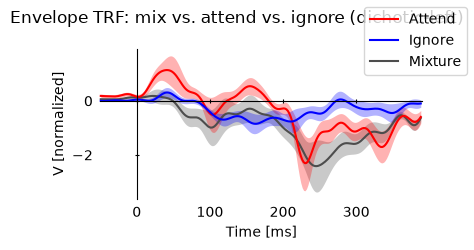

In [47]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (dichotic-left)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [48]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 46     0.0009484
02        mix                 48      4.41e-05
03        mix                 41      0.000555
04        mix                 41     -0.001061
05        mix                 50    -0.0002775
06        mix                 41     -0.001142
07        mix                 50     0.0002022
08        mix                 41      0.001854
09        mix                 64     0.0001301
10        mix                 46     0.0003028
11        mix                 41     0.0005388
12        mix                 64    -0.0001923
13        mix                 58     0.0009024
01        attend              50      0.006477
02        attend              46     0.0005048
03        attend              41    -0.0002593
04        attend              41     0.0003922
05        attend              41      0.001852
06        attend              41    -0.0001379
07        attend              46      0.00472

In [49]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 1.74 p = .108,t12 = 0.92 p = .374
attend,,t12 = 0.00 p = 1.000


,attend,ignore
mix,t12 = -0.77 p = .457,t12 = -7.96*** p < .001
attend,,t12 = -7.57*** p < .001


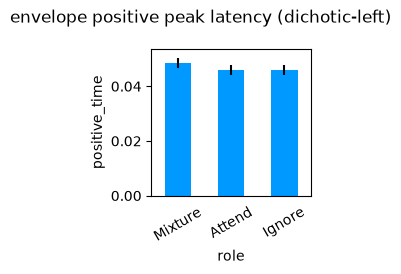

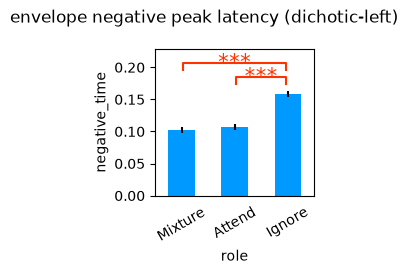

In [50]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (dichotic-left)')
p.set_xtick_rotation(30)

In [51]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -2.06 p = .062,t12 = -0.72 p = .485
attend,,t12 = 1.88 p = .084


,attend,ignore
mix,t12 = -1.55 p = .146,t12 = -1.32 p = .210
attend,,t12 = 0.26 p = .796


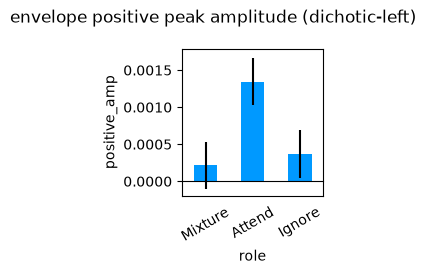

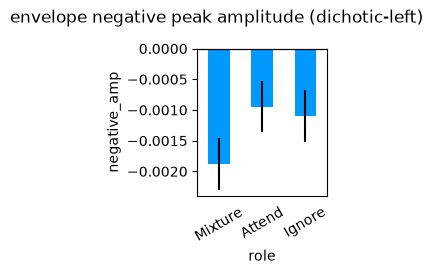

In [52]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)

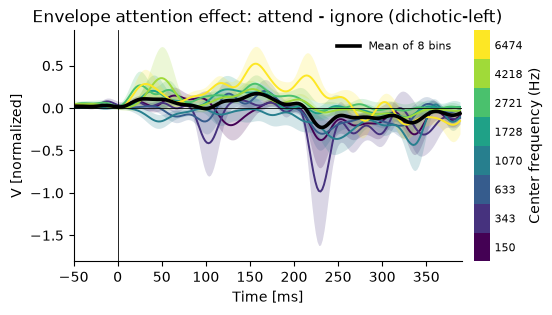

In [53]:
# Envelope attention effect: attend - ignore (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (dichotic-left)', subtract='bg_gammatone_8')

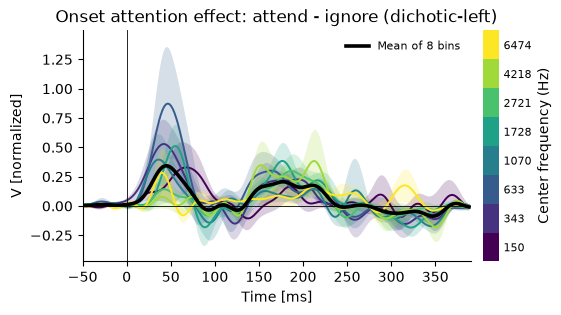

In [54]:
# Onset attention effect: attend - ignore (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (dichotic-left)', subtract='bg_gammatone_on_8')